In [9]:
# ══════════════════════════════════════════════════════════════════
# CELLULE 1 — INSTALLATION + IMPORTS
# HealixDz Cardiac Segmentation AI v1.0
# ACDC IRM : LV + RV + MYO
# CT Heart : cœur entier binaire
# ══════════════════════════════════════════════════════════════════

!pip install segmentation-models-pytorch albumentations h5py SimpleITK --quiet

import os, cv2, json, time, warnings, gc, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from pathlib import Path
from collections import Counter
from sklearn.model_selection import train_test_split

import h5py
import SimpleITK as sitk

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torch.cuda.amp import GradScaler, autocast

import segmentation_models_pytorch as smp
import albumentations as A
from albumentations.pytorch import ToTensorV2

warnings.filterwarnings("ignore")

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"✅ Device : {device}")
if torch.cuda.is_available():
    print(f"✅ GPU    : {torch.cuda.get_device_name(0)}")
    print(f"✅ VRAM   : {torch.cuda.get_device_properties(0).total_memory/1e9:.1f} GB")
print(f"✅ PyTorch : {torch.__version__}")


✅ Device : cuda
✅ GPU    : Tesla T4
✅ VRAM   : 15.6 GB
✅ PyTorch : 2.10.0+cu128


In [10]:
# ══════════════════════════════════════════════════════════════════
# CELLULE 2 — CONFIGURATION + INSPECTION
# ══════════════════════════════════════════════════════════════════

ACDC_PATH = "/kaggle/input/datasets/anhoangvo/acdc-dataset/ACDC_preprocessed"
CT_PATH   = "/kaggle/input/datasets/andrewmvd/heart-segmentation-in-ct-images"

CFG = {
    "acdc_path": ACDC_PATH,
    "ct_path": CT_PATH,
    "output_path": "/kaggle/working",
    "img_size": 256,
    "batch_size": 12,
    "num_workers": 2,
    "epochs_acdc": 40,
    "epochs_ct": 35,
    "lr_acdc": 1e-4,
    "lr_ct": 1e-4,
    "weight_decay": 1e-4,
    "patience": 8,
    "mixed_precision": True,
    "encoder": "efficientnet-b4",
    "encoder_weights": "imagenet",
    "min_cardiac_pct": 0.001,
    "min_heart_pct": 0.001,
    "acdc_model": "healixdz_cardiac_acdc_unet_best.pth",
    "ct_model": "healixdz_cardiac_ct_heart_unet_best.pth",
    "seed": 42,
}

ACDC_CLASSES = ["Background", "LV", "RV", "MYO"]
NUM_SEG_CLS = len(ACDC_CLASSES)

def seed_everything(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

seed_everything(CFG["seed"])

print("📁 Chemins datasets :")
for name, path in [("ACDC", CFG["acdc_path"]), ("CT Heart", CFG["ct_path"])]:
    p = Path(path)
    print(f"   {'✅' if p.exists() else '❌'} {name:<10}: {path}")

def inspect_dataset(path, max_examples=30):
    path = Path(path)
    print(f"\n📂 Inspection : {path}")
    print("Existe :", path.exists())
    if not path.exists():
        return
    files = [p for p in path.rglob("*") if p.is_file()]
    print("\nExtensions :")
    for ext, n in Counter([p.suffix.lower() for p in files]).most_common(20):
        print(f"  {ext}: {n}")
    print("\nExemples fichiers :")
    for p in files[:max_examples]:
        print(" ", p.relative_to(path))

inspect_dataset("/kaggle/input/datasets/anhoangvo/acdc-dataset")
inspect_dataset(CFG["ct_path"])

print("\n✅ Configuration Cardiac Segmentation AI v1.0")
print(f"   Classes ACDC : {ACDC_CLASSES}")
print(f"   Encoder      : {CFG['encoder']}")
print(f"   Image size   : {CFG['img_size']}")


📁 Chemins datasets :
   ✅ ACDC      : /kaggle/input/datasets/anhoangvo/acdc-dataset/ACDC_preprocessed
   ✅ CT Heart  : /kaggle/input/datasets/andrewmvd/heart-segmentation-in-ct-images

📂 Inspection : /kaggle/input/datasets/anhoangvo/acdc-dataset
Existe : True

Extensions :
  .h5: 2212

Exemples fichiers :
  ACDC_preprocessed/ACDC_training_slices/patient061_frame01_slice_7.h5
  ACDC_preprocessed/ACDC_training_slices/patient067_frame10_slice_0.h5
  ACDC_preprocessed/ACDC_training_slices/patient050_frame12_slice_6.h5
  ACDC_preprocessed/ACDC_training_slices/patient045_frame01_slice_7.h5
  ACDC_preprocessed/ACDC_training_slices/patient007_frame01_slice_5.h5
  ACDC_preprocessed/ACDC_training_slices/patient030_frame01_slice_1.h5
  ACDC_preprocessed/ACDC_training_slices/patient033_frame01_slice_7.h5
  ACDC_preprocessed/ACDC_training_slices/patient031_frame10_slice_8.h5
  ACDC_preprocessed/ACDC_training_slices/patient099_frame09_slice_9.h5
  ACDC_preprocessed/ACDC_training_slices/patient025_fr

In [11]:
# ══════════════════════════════════════════════════════════════════
# CELLULE 3 — CHARGEMENT ACDC .H5
# ══════════════════════════════════════════════════════════════════

def detect_h5_keys(h5_path):
    with h5py.File(h5_path, "r") as f:
        keys = list(f.keys())
        img_key = None
        mask_key = None
        for k in keys:
            kl = k.lower()
            if kl in ["image", "img", "x", "data"]:
                img_key = k
            if kl in ["label", "mask", "seg", "y", "gt"]:
                mask_key = k
        if img_key is None or mask_key is None:
            for k in keys:
                kl = k.lower()
                if img_key is None and ("image" in kl or "img" in kl):
                    img_key = k
                if mask_key is None and ("label" in kl or "mask" in kl or "seg" in kl):
                    mask_key = k
        return keys, img_key, mask_key

def load_acdc_h5_index(acdc_root):
    acdc_root = Path(acdc_root)
    h5_files = list(acdc_root.rglob("*.h5"))
    print(f"📂 ACDC root utilisé : {acdc_root}")
    print(f"✅ Fichiers .h5 trouvés : {len(h5_files):,}")
    if h5_files:
        keys, img_key, mask_key = detect_h5_keys(h5_files[0])
        print(f"   Exemple : {h5_files[0].name}")
        print(f"   Clés    : {keys}")
        print(f"   img_key={img_key} | mask_key={mask_key}")
    index = []
    skipped = 0
    for h5_path in h5_files:
        try:
            keys, img_key, mask_key = detect_h5_keys(h5_path)
            if img_key is None or mask_key is None:
                skipped += 1
                continue
            with h5py.File(h5_path, "r") as f:
                mask = np.array(f[mask_key])
            if mask.ndim == 2:
                if (mask > 0).mean() >= CFG["min_cardiac_pct"]:
                    index.append(("acdc_h5_2d", str(h5_path), img_key, mask_key))
            elif mask.ndim == 3:
                for s in range(mask.shape[-1]):
                    m = mask[:, :, s]
                    if (m > 0).mean() >= CFG["min_cardiac_pct"]:
                        index.append(("acdc_h5_3d", str(h5_path), img_key, mask_key, s))
        except Exception as e:
            skipped += 1
            if skipped <= 5:
                print("   ⚠️ Erreur H5 :", h5_path.name, e)
    print(f"✅ ACDC index corrigé : {len(index):,} coupes")
    print(f"   Fichiers ignorés : {skipped:,}")
    return index

print("📂 Chargement ACDC .h5 corrigé...")
acdc_index = load_acdc_h5_index(CFG["acdc_path"])
if len(acdc_index) > 0:
    acdc_train, acdc_tmp = train_test_split(acdc_index, test_size=0.30, random_state=42)
    acdc_val, acdc_test = train_test_split(acdc_tmp, test_size=0.50, random_state=42)
    print("\n📊 Splits ACDC :")
    print(f"   Train : {len(acdc_train):,}")
    print(f"   Val   : {len(acdc_val):,}")
    print(f"   Test  : {len(acdc_test):,}")
else:
    acdc_train, acdc_val, acdc_test = [], [], []
    print("❌ Aucun sample ACDC trouvé")


📂 Chargement ACDC .h5 corrigé...
📂 ACDC root utilisé : /kaggle/input/datasets/anhoangvo/acdc-dataset/ACDC_preprocessed
✅ Fichiers .h5 trouvés : 2,212
   Exemple : patient061_frame01_slice_7.h5
   Clés    : ['image', 'label', 'scribble']
   img_key=image | mask_key=label
✅ ACDC index corrigé : 22,972 coupes
   Fichiers ignorés : 0

📊 Splits ACDC :
   Train : 16,080
   Val   : 3,446
   Test  : 3,446


In [12]:
# ══════════════════════════════════════════════════════════════════
# CELLULE 4 — CHARGEMENT CT HEART .MHD / .RAW / .ZRAW
# ══════════════════════════════════════════════════════════════════

def load_ct_heart_mhd_index(ct_root):
    ct_root = Path(ct_root)
    index = []
    patient_dirs = []
    for split in ["Training Set", "Testing Set"]:
        split_dir = ct_root / split
        if split_dir.exists():
            patient_dirs.extend([p for p in split_dir.iterdir() if p.is_dir()])
    print(f"📂 CT Heart root utilisé : {ct_root}")
    print(f"✅ Dossiers patients trouvés : {len(patient_dirs):,}")
    for pdir in sorted(patient_dirs):
        img_path = pdir / "image.mhd"
        mask_path = pdir / "gt_std.mhd"
        if not mask_path.exists():
            mask_path = pdir / "gt_noclip.mhd"
        if not img_path.exists() or not mask_path.exists():
            continue
        try:
            mask_vol = sitk.GetArrayFromImage(sitk.ReadImage(str(mask_path))).astype(np.uint8)
            for s in range(mask_vol.shape[0]):
                m = mask_vol[s]
                if (m > 0).mean() >= CFG["min_heart_pct"]:
                    index.append(("ct_mhd", str(img_path), str(mask_path), s))
            del mask_vol
        except Exception as e:
            print("   ⚠️ Erreur CT :", pdir.name, e)
    print(f"✅ CT Heart index corrigé : {len(index):,} coupes")
    return index

print("📂 Chargement CT Heart corrigé...")
ct_index = load_ct_heart_mhd_index(CFG["ct_path"])
if len(ct_index) > 0:
    ct_train, ct_tmp = train_test_split(ct_index, test_size=0.30, random_state=42)
    ct_val, ct_test = train_test_split(ct_tmp, test_size=0.50, random_state=42)
    print("\n📊 Splits CT Heart :")
    print(f"   Train : {len(ct_train):,}")
    print(f"   Val   : {len(ct_val):,}")
    print(f"   Test  : {len(ct_test):,}")
else:
    ct_train, ct_val, ct_test = [], [], []
    print("❌ Aucun sample CT trouvé")
print("\n📊 Résumé corpus total :")
print(f"   ACDC IRM : {len(acdc_index):,} coupes")
print(f"   CT Heart : {len(ct_index):,} coupes")
print(f"   TOTAL    : {len(acdc_index) + len(ct_index):,} coupes")


📂 Chargement CT Heart corrigé...
📂 CT Heart root utilisé : /kaggle/input/datasets/andrewmvd/heart-segmentation-in-ct-images
✅ Dossiers patients trouvés : 30
✅ CT Heart index corrigé : 1,229 coupes

📊 Splits CT Heart :
   Train : 860
   Val   : 184
   Test  : 185

📊 Résumé corpus total :
   ACDC IRM : 22,972 coupes
   CT Heart : 1,229 coupes
   TOTAL    : 24,201 coupes


In [13]:
# ══════════════════════════════════════════════════════════════════
# CELLULE 5 — AUGMENTATIONS + DATASETS PYTORCH
# ══════════════════════════════════════════════════════════════════

def get_train_transforms(img_size=256):
    return A.Compose([
        A.Resize(img_size, img_size),
        A.HorizontalFlip(p=0.5),
        A.Rotate(limit=12, border_mode=cv2.BORDER_CONSTANT, p=0.35),
        A.ShiftScaleRotate(shift_limit=0.04, scale_limit=0.08, rotate_limit=10,
                           border_mode=cv2.BORDER_CONSTANT, p=0.35),
        A.RandomBrightnessContrast(p=0.35),
        A.GaussNoise(var_limit=(5, 25), p=0.20),
        A.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
        ToTensorV2(),
    ])

def get_val_transforms(img_size=256):
    return A.Compose([
        A.Resize(img_size, img_size),
        A.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
        ToTensorV2(),
    ])

train_tfm = get_train_transforms(CFG["img_size"])
val_tfm = get_val_transforms(CFG["img_size"])

class ACDCDataset(Dataset):
    def __init__(self, index, transforms=None):
        self.index = index
        self.transforms = transforms
    def __len__(self):
        return len(self.index)
    def __getitem__(self, idx):
        item = self.index[idx]
        try:
            mode = item[0]
            if mode == "acdc_h5_2d":
                _, h5_path, img_key, mask_key = item
                with h5py.File(h5_path, "r") as f:
                    img = np.array(f[img_key]).astype(np.float32)
                    mask = np.array(f[mask_key]).astype(np.uint8)
            else:
                _, h5_path, img_key, mask_key, s = item
                with h5py.File(h5_path, "r") as f:
                    img_v = np.array(f[img_key]).astype(np.float32)
                    mask_v = np.array(f[mask_key]).astype(np.uint8)
                img = img_v[:, :, s]
                mask = mask_v[:, :, s]

            # ACDC original fréquent : 1=RV, 2=MYO, 3=LV
            # HealixDz : 1=LV, 2=RV, 3=MYO
            remap = np.zeros_like(mask, dtype=np.uint8)
            remap[mask == 3] = 1
            remap[mask == 1] = 2
            remap[mask == 2] = 3
            mask = remap

            valid = img > 0
            if valid.sum() > 0:
                img = img.copy()
                img[valid] = (img[valid] - img[valid].mean()) / (img[valid].std() + 1e-8)
            img = np.clip(img, -3, 3)
            img = ((img + 3) / 6 * 255).clip(0, 255).astype(np.uint8)
            img_rgb = cv2.cvtColor(img, cv2.COLOR_GRAY2RGB)
        except Exception:
            img_rgb = np.zeros((CFG["img_size"], CFG["img_size"], 3), dtype=np.uint8)
            mask = np.zeros((CFG["img_size"], CFG["img_size"]), dtype=np.uint8)

        if self.transforms:
            aug = self.transforms(image=img_rgb, mask=mask)
            return aug["image"].float(), aug["mask"].long()
        return torch.tensor(img_rgb.transpose(2,0,1)).float()/255.0, torch.tensor(mask).long()

class CTHeartDataset(Dataset):
    def __init__(self, index, transforms=None):
        self.index = index
        self.transforms = transforms
    def __len__(self):
        return len(self.index)
    def __getitem__(self, idx):
        try:
            _, img_path, mask_path, s = self.index[idx]
            img_vol = sitk.GetArrayFromImage(sitk.ReadImage(img_path)).astype(np.float32)
            mask_vol = sitk.GetArrayFromImage(sitk.ReadImage(mask_path)).astype(np.uint8)
            img = img_vol[s]
            mask = (mask_vol[s] > 0).astype(np.uint8)
            img = np.clip(img, -200, 500)
            img = ((img + 200) / 700 * 255).clip(0, 255).astype(np.uint8)
            img_rgb = cv2.cvtColor(img, cv2.COLOR_GRAY2RGB)
        except Exception:
            img_rgb = np.zeros((CFG["img_size"], CFG["img_size"], 3), dtype=np.uint8)
            mask = np.zeros((CFG["img_size"], CFG["img_size"]), dtype=np.uint8)

        if self.transforms:
            aug = self.transforms(image=img_rgb, mask=mask)
            return aug["image"].float(), aug["mask"].long()
        return torch.tensor(img_rgb.transpose(2,0,1)).float()/255.0, torch.tensor(mask).long()

acdc_train_ds = ACDCDataset(acdc_train, train_tfm)
acdc_val_ds   = ACDCDataset(acdc_val, val_tfm)
acdc_test_ds  = ACDCDataset(acdc_test, val_tfm)

ct_train_ds = CTHeartDataset(ct_train, train_tfm)
ct_val_ds   = CTHeartDataset(ct_val, val_tfm)
ct_test_ds  = CTHeartDataset(ct_test, val_tfm)

print("✅ Datasets créés :")
print(f"   ACDC train/val/test : {len(acdc_train_ds):,}/{len(acdc_val_ds):,}/{len(acdc_test_ds):,}")
print(f"   CT train/val/test   : {len(ct_train_ds):,}/{len(ct_val_ds):,}/{len(ct_test_ds):,}")


✅ Datasets créés :
   ACDC train/val/test : 16,080/3,446/3,446
   CT train/val/test   : 860/184/185


✅ DataLoaders :
   ✅ ACDC train: images=(12, 3, 256, 256) masks=(12, 256, 256)
   ✅ ACDC val: images=(12, 3, 256, 256) masks=(12, 256, 256)
   ✅ CT train: images=(12, 3, 256, 256) masks=(12, 256, 256)
   ✅ CT val: images=(12, 3, 256, 256) masks=(12, 256, 256)


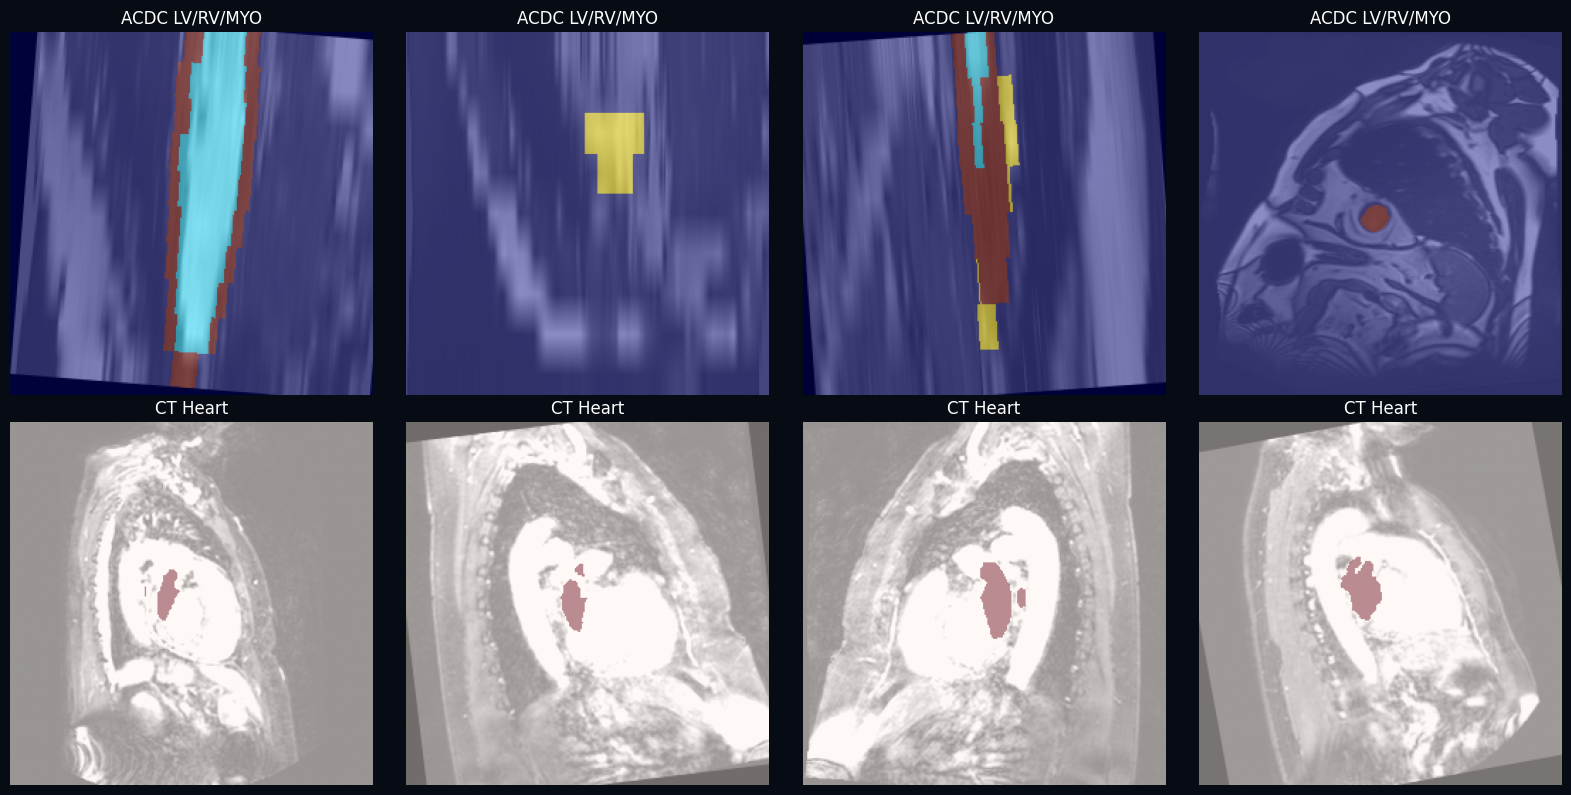

In [14]:
# ══════════════════════════════════════════════════════════════════
# CELLULE 6 — DATALOADERS + VISUALISATION RAPIDE
# ══════════════════════════════════════════════════════════════════

def make_loader(ds, shuffle=False, batch_size=None):
    if batch_size is None:
        batch_size = CFG["batch_size"]
    if len(ds) == 0:
        return None
    return DataLoader(ds, batch_size=batch_size, shuffle=shuffle,
                      num_workers=CFG["num_workers"], pin_memory=True)

acdc_train_loader = make_loader(acdc_train_ds, True)
acdc_val_loader   = make_loader(acdc_val_ds, False)
acdc_test_loader  = make_loader(acdc_test_ds, False)
ct_train_loader   = make_loader(ct_train_ds, True)
ct_val_loader     = make_loader(ct_val_ds, False)
ct_test_loader    = make_loader(ct_test_ds, False)

print("✅ DataLoaders :")
for name, loader in [("ACDC train", acdc_train_loader), ("ACDC val", acdc_val_loader),
                     ("CT train", ct_train_loader), ("CT val", ct_val_loader)]:
    if loader is None:
        print(f"   ❌ {name}: vide")
    else:
        imgs, masks = next(iter(loader))
        print(f"   ✅ {name}: images={tuple(imgs.shape)} masks={tuple(masks.shape)}")

def denorm_img(t):
    img = t.permute(1, 2, 0).cpu().numpy()
    img = img * np.array([0.229,0.224,0.225]) + np.array([0.485,0.456,0.406])
    return np.clip(img, 0, 1)

def visualize_samples():
    rows = int(len(acdc_train_ds)>0) + int(len(ct_train_ds)>0)
    if rows == 0:
        print("❌ Aucun sample à visualiser")
        return
    fig, axes = plt.subplots(rows, 4, figsize=(16, 4*rows), facecolor="#060B14")
    if rows == 1:
        axes = np.expand_dims(axes, 0)
    r = 0
    if len(acdc_train_ds) > 0:
        for i in range(4):
            img, mask = acdc_train_ds[min(i, len(acdc_train_ds)-1)]
            axes[r,i].imshow(denorm_img(img))
            axes[r,i].imshow(mask.numpy(), alpha=0.45, cmap="jet", vmin=0, vmax=3)
            axes[r,i].set_title("ACDC LV/RV/MYO", color="white")
            axes[r,i].axis("off")
        r += 1
    if len(ct_train_ds) > 0:
        for i in range(4):
            img, mask = ct_train_ds[min(i, len(ct_train_ds)-1)]
            axes[r,i].imshow(denorm_img(img))
            axes[r,i].imshow(mask.numpy(), alpha=0.45, cmap="Reds", vmin=0, vmax=1)
            axes[r,i].set_title("CT Heart", color="white")
            axes[r,i].axis("off")
    plt.tight_layout()
    plt.show()

visualize_samples()


In [15]:
# ══════════════════════════════════════════════════════════════════
# CELLULE 7 — ARCHITECTURES U-NET
# ══════════════════════════════════════════════════════════════════

def build_acdc_unet():
    return smp.Unet(encoder_name=CFG["encoder"], encoder_weights=CFG["encoder_weights"],
                    in_channels=3, classes=NUM_SEG_CLS,
                    decoder_channels=(256,128,64,32,16), activation=None)

def build_ct_unet():
    return smp.Unet(encoder_name=CFG["encoder"], encoder_weights=CFG["encoder_weights"],
                    in_channels=3, classes=1,
                    decoder_channels=(256,128,64,32,16), activation=None)

tmp_acdc = build_acdc_unet()
tmp_ct = build_ct_unet()
print(f"✅ U-Net ACDC : {sum(p.numel() for p in tmp_acdc.parameters())/1e6:.1f}M paramètres")
print(f"✅ U-Net CT   : {sum(p.numel() for p in tmp_ct.parameters())/1e6:.1f}M paramètres")
del tmp_acdc, tmp_ct
gc.collect()


config.json:   0%|          | 0.00/106 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/77.9M [00:00<?, ?B/s]

✅ U-Net ACDC : 20.2M paramètres
✅ U-Net CT   : 20.2M paramètres


17715

In [16]:
# ══════════════════════════════════════════════════════════════════
# CELLULE 8 — LOSSES + MÉTRIQUES
# ══════════════════════════════════════════════════════════════════

class DiceCELoss(nn.Module):
    def __init__(self, n_classes=4, dice_w=0.5, ce_w=0.5, smooth=1e-6):
        super().__init__()
        self.n_classes = n_classes
        self.dice_w = dice_w
        self.ce_w = ce_w
        self.smooth = smooth
        self.ce = nn.CrossEntropyLoss()

    def forward(self, logits, targets):
        ce_loss = self.ce(logits, targets.long())
        probs = torch.softmax(logits, dim=1)
        onehot = F.one_hot(targets.long(), self.n_classes).permute(0,3,1,2).float()
        dice_losses = []
        for c in range(1, self.n_classes):
            p = probs[:, c]
            t = onehot[:, c]
            inter = (p*t).sum(dim=(1,2))
            union = p.sum(dim=(1,2)) + t.sum(dim=(1,2))
            dice = (2*inter + self.smooth) / (union + self.smooth)
            dice_losses.append(1 - dice.mean())
        return self.ce_w*ce_loss + self.dice_w*torch.stack(dice_losses).mean()

class BCEDiceLoss(nn.Module):
    def __init__(self, bce_w=0.5, dice_w=0.5, smooth=1e-6):
        super().__init__()
        self.bce_w = bce_w
        self.dice_w = dice_w
        self.smooth = smooth
        self.bce = nn.BCEWithLogitsLoss()

    def forward(self, logits, targets):
        targets = targets.float().unsqueeze(1) if targets.ndim == 3 else targets.float()
        bce = self.bce(logits, targets)
        probs = torch.sigmoid(logits)
        inter = (probs*targets).sum(dim=(2,3))
        union = probs.sum(dim=(2,3)) + targets.sum(dim=(2,3))
        dice = (2*inter + self.smooth) / (union + self.smooth)
        return self.bce_w*bce + self.dice_w*(1 - dice.mean())

def dice_per_class(logits, masks, n_classes=4, smooth=1e-6):
    preds = torch.argmax(logits, dim=1)
    scores, vals = {}, []
    for c, name in zip([1,2,3], ["LV","RV","MYO"]):
        p = (preds == c).float()
        t = (masks == c).float()
        inter = (p*t).sum(dim=(1,2))
        union = p.sum(dim=(1,2)) + t.sum(dim=(1,2))
        dice = ((2*inter + smooth) / (union + smooth)).mean().item()
        scores[name] = dice
        vals.append(dice)
    scores["mean"] = float(np.mean(vals))
    return scores

def dice_binary(logits, masks, smooth=1e-6):
    if masks.ndim == 3:
        masks = masks.unsqueeze(1)
    masks = masks.float()
    preds = (torch.sigmoid(logits) > 0.5).float()
    inter = (preds*masks).sum(dim=(2,3))
    union = preds.sum(dim=(2,3)) + masks.sum(dim=(2,3))
    return ((2*inter + smooth) / (union + smooth)).mean().item()

def iou_binary(logits, masks, smooth=1e-6):
    if masks.ndim == 3:
        masks = masks.unsqueeze(1)
    masks = masks.float()
    preds = (torch.sigmoid(logits) > 0.5).float()
    inter = (preds*masks).sum(dim=(2,3))
    union = preds.sum(dim=(2,3)) + masks.sum(dim=(2,3)) - inter
    return ((inter + smooth) / (union + smooth)).mean().item()

criterion_acdc = DiceCELoss(n_classes=NUM_SEG_CLS)
criterion_ct = BCEDiceLoss()
print("✅ Loss ACDC : Dice + CrossEntropy")
print("✅ Loss CT   : BCE + Dice")


✅ Loss ACDC : Dice + CrossEntropy
✅ Loss CT   : BCE + Dice


In [17]:
# ══════════════════════════════════════════════════════════════════
# CELLULE 9 — FONCTION ENTRAÎNEMENT GÉNÉRIQUE
# ══════════════════════════════════════════════════════════════════

def train_model(model, train_loader, val_loader, save_path, label, epochs, lr,
                criterion, metric_fn, mode="acdc"):
    if train_loader is None or val_loader is None:
        print(f"❌ {label} ignoré : DataLoader vide")
        return {"train_loss": [], "val_loss": [], "train_metric": [], "val_metric": [], "lr": []}, 0.0

    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=CFG["weight_decay"])
    scheduler = torch.optim.lr_scheduler.CosineAnnealingWarmRestarts(optimizer, T_0=10, T_mult=2, eta_min=1e-6)
    scaler = GradScaler(enabled=(CFG["mixed_precision"] and device.type == "cuda"))

    history = {"train_loss": [], "val_loss": [], "train_metric": [], "val_metric": [], "lr": []}
    best_metric, patience_cnt = 0.0, 0

    print(f"\n{'═'*66}")
    print(f"  ENTRAÎNEMENT — {label}")
    print(f"  LR={lr} | Epochs={epochs} | Mode={mode}")
    print(f"{'═'*66}")

    for epoch in range(1, epochs+1):
        t0 = time.time()
        model.train()
        tr_l, tr_m = 0.0, 0.0

        for imgs, masks in train_loader:
            imgs, masks = imgs.to(device, non_blocking=True), masks.to(device, non_blocking=True)
            optimizer.zero_grad(set_to_none=True)
            with autocast(enabled=(CFG["mixed_precision"] and device.type == "cuda")):
                logits = model(imgs)
                loss = criterion(logits, masks)
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(optimizer)
            scaler.update()
            tr_l += loss.item()
            tr_m += metric_fn(logits.detach(), masks)["mean"] if mode == "acdc" else metric_fn(logits.detach(), masks)

        tr_l /= len(train_loader)
        tr_m /= len(train_loader)

        model.eval()
        vl_l, vl_m = 0.0, 0.0
        with torch.no_grad():
            for imgs, masks in val_loader:
                imgs, masks = imgs.to(device, non_blocking=True), masks.to(device, non_blocking=True)
                with autocast(enabled=(CFG["mixed_precision"] and device.type == "cuda")):
                    logits = model(imgs)
                    loss = criterion(logits, masks)
                vl_l += loss.item()
                vl_m += metric_fn(logits, masks)["mean"] if mode == "acdc" else metric_fn(logits, masks)

        vl_l /= len(val_loader)
        vl_m /= len(val_loader)
        scheduler.step()
        lr_now = optimizer.param_groups[0]["lr"]

        history["train_loss"].append(tr_l)
        history["val_loss"].append(vl_l)
        history["train_metric"].append(tr_m)
        history["val_metric"].append(vl_m)
        history["lr"].append(lr_now)

        print(f"Ép {epoch:03d}/{epochs} | Loss {tr_l:.4f}/{vl_l:.4f} | Dice {tr_m:.4f}/{vl_m:.4f} | LR {lr_now:.2e} | {time.time()-t0:.0f}s")

        if vl_m > best_metric:
            best_metric, patience_cnt = vl_m, 0
            torch.save({"epoch": epoch, "model_state": model.state_dict(), "best_metric": best_metric,
                        "val_metric": vl_m, "val_loss": vl_l, "mode": mode,
                        "label": label, "history": history, "cfg": CFG}, save_path)
            print(f"  ✅ Best {label} — Dice={best_metric:.4f}")
        else:
            patience_cnt += 1
            print(f"  Patience : {patience_cnt}/{CFG['patience']}")
            if patience_cnt >= CFG["patience"]:
                print("\n⏹️ Early stopping")
                break

    print(f"\n🏆 Meilleur Dice {label} : {best_metric:.4f}")
    return history, best_metric


In [18]:
# ══════════════════════════════════════════════════════════════════
# CELLULE 10 — ENTRAÎNEMENT MODÈLE 1 : ACDC IRM MULTI-CLASSES
# ══════════════════════════════════════════════════════════════════

if acdc_train_loader is not None and acdc_val_loader is not None:
    print("MODÈLE 1 — ACDC IRM : LV + RV + MYO\n")
    model_acdc = build_acdc_unet().to(device)
    history_acdc, best_acdc = train_model(
        model=model_acdc,
        train_loader=acdc_train_loader,
        val_loader=acdc_val_loader,
        save_path=f"{CFG['output_path']}/{CFG['acdc_model']}",
        label="ACDC IRM — LV/RV/MYO",
        epochs=CFG["epochs_acdc"],
        lr=CFG["lr_acdc"],
        criterion=criterion_acdc,
        metric_fn=dice_per_class,
        mode="acdc",
    )
else:
    print("⚠️ ACDC vide → entraînement ACDC ignoré")
    history_acdc, best_acdc = {"train_loss": [], "val_loss": [], "train_metric": [], "val_metric": [], "lr": []}, 0.0


MODÈLE 1 — ACDC IRM : LV + RV + MYO


══════════════════════════════════════════════════════════════════
  ENTRAÎNEMENT — ACDC IRM — LV/RV/MYO
  LR=0.0001 | Epochs=40 | Mode=acdc
══════════════════════════════════════════════════════════════════
Ép 001/40 | Loss 0.4097/0.2927 | Dice 0.5400/0.7520 | LR 9.76e-05 | 352s
  ✅ Best ACDC IRM — LV/RV/MYO — Dice=0.7520
Ép 002/40 | Loss 0.2997/0.2717 | Dice 0.6894/0.7664 | LR 9.05e-05 | 323s
  ✅ Best ACDC IRM — LV/RV/MYO — Dice=0.7664
Ép 003/40 | Loss 0.2800/0.2618 | Dice 0.7362/0.7786 | LR 7.96e-05 | 339s
  ✅ Best ACDC IRM — LV/RV/MYO — Dice=0.7786
Ép 004/40 | Loss 0.2694/0.2540 | Dice 0.7626/0.8134 | LR 6.58e-05 | 326s
  ✅ Best ACDC IRM — LV/RV/MYO — Dice=0.8134
Ép 005/40 | Loss 0.2613/0.2478 | Dice 0.7860/0.8317 | LR 5.05e-05 | 326s
  ✅ Best ACDC IRM — LV/RV/MYO — Dice=0.8317
Ép 006/40 | Loss 0.2549/0.2455 | Dice 0.8032/0.8375 | LR 3.52e-05 | 342s
  ✅ Best ACDC IRM — LV/RV/MYO — Dice=0.8375
Ép 007/40 | Loss 0.2503/0.2404 | Dice 0.8164/0.8524 

In [19]:
# ══════════════════════════════════════════════════════════════════
# CELLULE 11 — ENTRAÎNEMENT MODÈLE 2 : CT HEART BINAIRE
# ══════════════════════════════════════════════════════════════════

if "model_acdc" in globals():
    del model_acdc
torch.cuda.empty_cache()
gc.collect()
print("✅ GPU libéré\n")

if ct_train_loader is not None and ct_val_loader is not None:
    print("MODÈLE 2 — CT Heart : Cœur entier binaire\n")
    model_ct = build_ct_unet().to(device)
    history_ct, best_ct = train_model(
        model=model_ct,
        train_loader=ct_train_loader,
        val_loader=ct_val_loader,
        save_path=f"{CFG['output_path']}/{CFG['ct_model']}",
        label="CT Heart — Heart binary",
        epochs=CFG["epochs_ct"],
        lr=CFG["lr_ct"],
        criterion=criterion_ct,
        metric_fn=dice_binary,
        mode="ct",
    )
else:
    print("⚠️ CT Heart vide → entraînement CT ignoré")
    history_ct, best_ct = {"train_loss": [], "val_loss": [], "train_metric": [], "val_metric": [], "lr": []}, 0.0


✅ GPU libéré

MODÈLE 2 — CT Heart : Cœur entier binaire


══════════════════════════════════════════════════════════════════
  ENTRAÎNEMENT — CT Heart — Heart binary
  LR=0.0001 | Epochs=35 | Mode=ct
══════════════════════════════════════════════════════════════════
Ép 001/35 | Loss 0.6744/0.5994 | Dice 0.2199/0.4730 | LR 9.76e-05 | 83s
  ✅ Best CT Heart — Heart binary — Dice=0.4730
Ép 002/35 | Loss 0.5537/0.5156 | Dice 0.6337/0.6828 | LR 9.05e-05 | 66s
  ✅ Best CT Heart — Heart binary — Dice=0.6828
Ép 003/35 | Loss 0.4917/0.4660 | Dice 0.7143/0.7621 | LR 7.96e-05 | 67s
  ✅ Best CT Heart — Heart binary — Dice=0.7621
Ép 004/35 | Loss 0.4496/0.4244 | Dice 0.7460/0.8261 | LR 6.58e-05 | 68s
  ✅ Best CT Heart — Heart binary — Dice=0.8261
Ép 005/35 | Loss 0.4161/0.3911 | Dice 0.7669/0.8074 | LR 5.05e-05 | 68s
  Patience : 1/8
Ép 006/35 | Loss 0.3884/0.3651 | Dice 0.7825/0.8269 | LR 3.52e-05 | 67s
  ✅ Best CT Heart — Heart binary — Dice=0.8269
Ép 007/35 | Loss 0.3671/0.3504 | Dice 0.7944/0.79

In [20]:
# ══════════════════════════════════════════════════════════════════
# CELLULE 12 — ÉVALUATION TEST SET
# ══════════════════════════════════════════════════════════════════

out = Path(CFG["output_path"])

def evaluate_acdc(model, loader):
    model.eval()
    dices = {"LV": [], "RV": [], "MYO": [], "mean": []}
    with torch.no_grad():
        for imgs, masks in loader:
            imgs, masks = imgs.to(device), masks.to(device)
            logits = model(imgs)
            d = dice_per_class(logits, masks)
            for k in dices:
                dices[k].append(d[k])
    return {k: float(np.mean(v)) if v else 0.0 for k, v in dices.items()}

def evaluate_ct(model, loader):
    model.eval()
    ds, js = [], []
    with torch.no_grad():
        for imgs, masks in loader:
            imgs, masks = imgs.to(device), masks.to(device)
            logits = model(imgs)
            ds.append(dice_binary(logits, masks))
            js.append(iou_binary(logits, masks))
    return {"dice": float(np.mean(ds)) if ds else 0.0, "iou": float(np.mean(js)) if js else 0.0}

test_acdc = {"LV": 0, "RV": 0, "MYO": 0, "mean": 0}
test_ct = {"dice": 0, "iou": 0}

if (out / CFG["acdc_model"]).exists() and acdc_test_loader is not None:
    model_acdc = build_acdc_unet().to(device)
    ckpt = torch.load(out / CFG["acdc_model"], map_location=device, weights_only=False)
    model_acdc.load_state_dict(ckpt["model_state"])
    test_acdc = evaluate_acdc(model_acdc, acdc_test_loader)
    print("\n" + "═"*60)
    print("TEST SET — ACDC IRM")
    print("═"*60)
    print(f"  LV Dice   : {test_acdc['LV']:.4f}")
    print(f"  RV Dice   : {test_acdc['RV']:.4f}")
    print(f"  MYO Dice  : {test_acdc['MYO']:.4f}")
    print(f"  Mean Dice : {test_acdc['mean']:.4f}")
else:
    print("⚠️ Modèle ACDC ou test loader absent")

if (out / CFG["ct_model"]).exists() and ct_test_loader is not None:
    model_ct = build_ct_unet().to(device)
    ckpt = torch.load(out / CFG["ct_model"], map_location=device, weights_only=False)
    model_ct.load_state_dict(ckpt["model_state"])
    test_ct = evaluate_ct(model_ct, ct_test_loader)
    print("\n" + "═"*60)
    print("TEST SET — CT HEART")
    print("═"*60)
    print(f"  Heart Dice : {test_ct['dice']:.4f}")
    print(f"  Heart IoU  : {test_ct['iou']:.4f}")
else:
    print("⚠️ Modèle CT ou test loader absent")



════════════════════════════════════════════════════════════
TEST SET — ACDC IRM
════════════════════════════════════════════════════════════
  LV Dice   : 0.9341
  RV Dice   : 0.8865
  MYO Dice  : 0.8922
  Mean Dice : 0.9043

════════════════════════════════════════════════════════════
TEST SET — CT HEART
════════════════════════════════════════════════════════════
  Heart Dice : 0.9216
  Heart IoU  : 0.8609


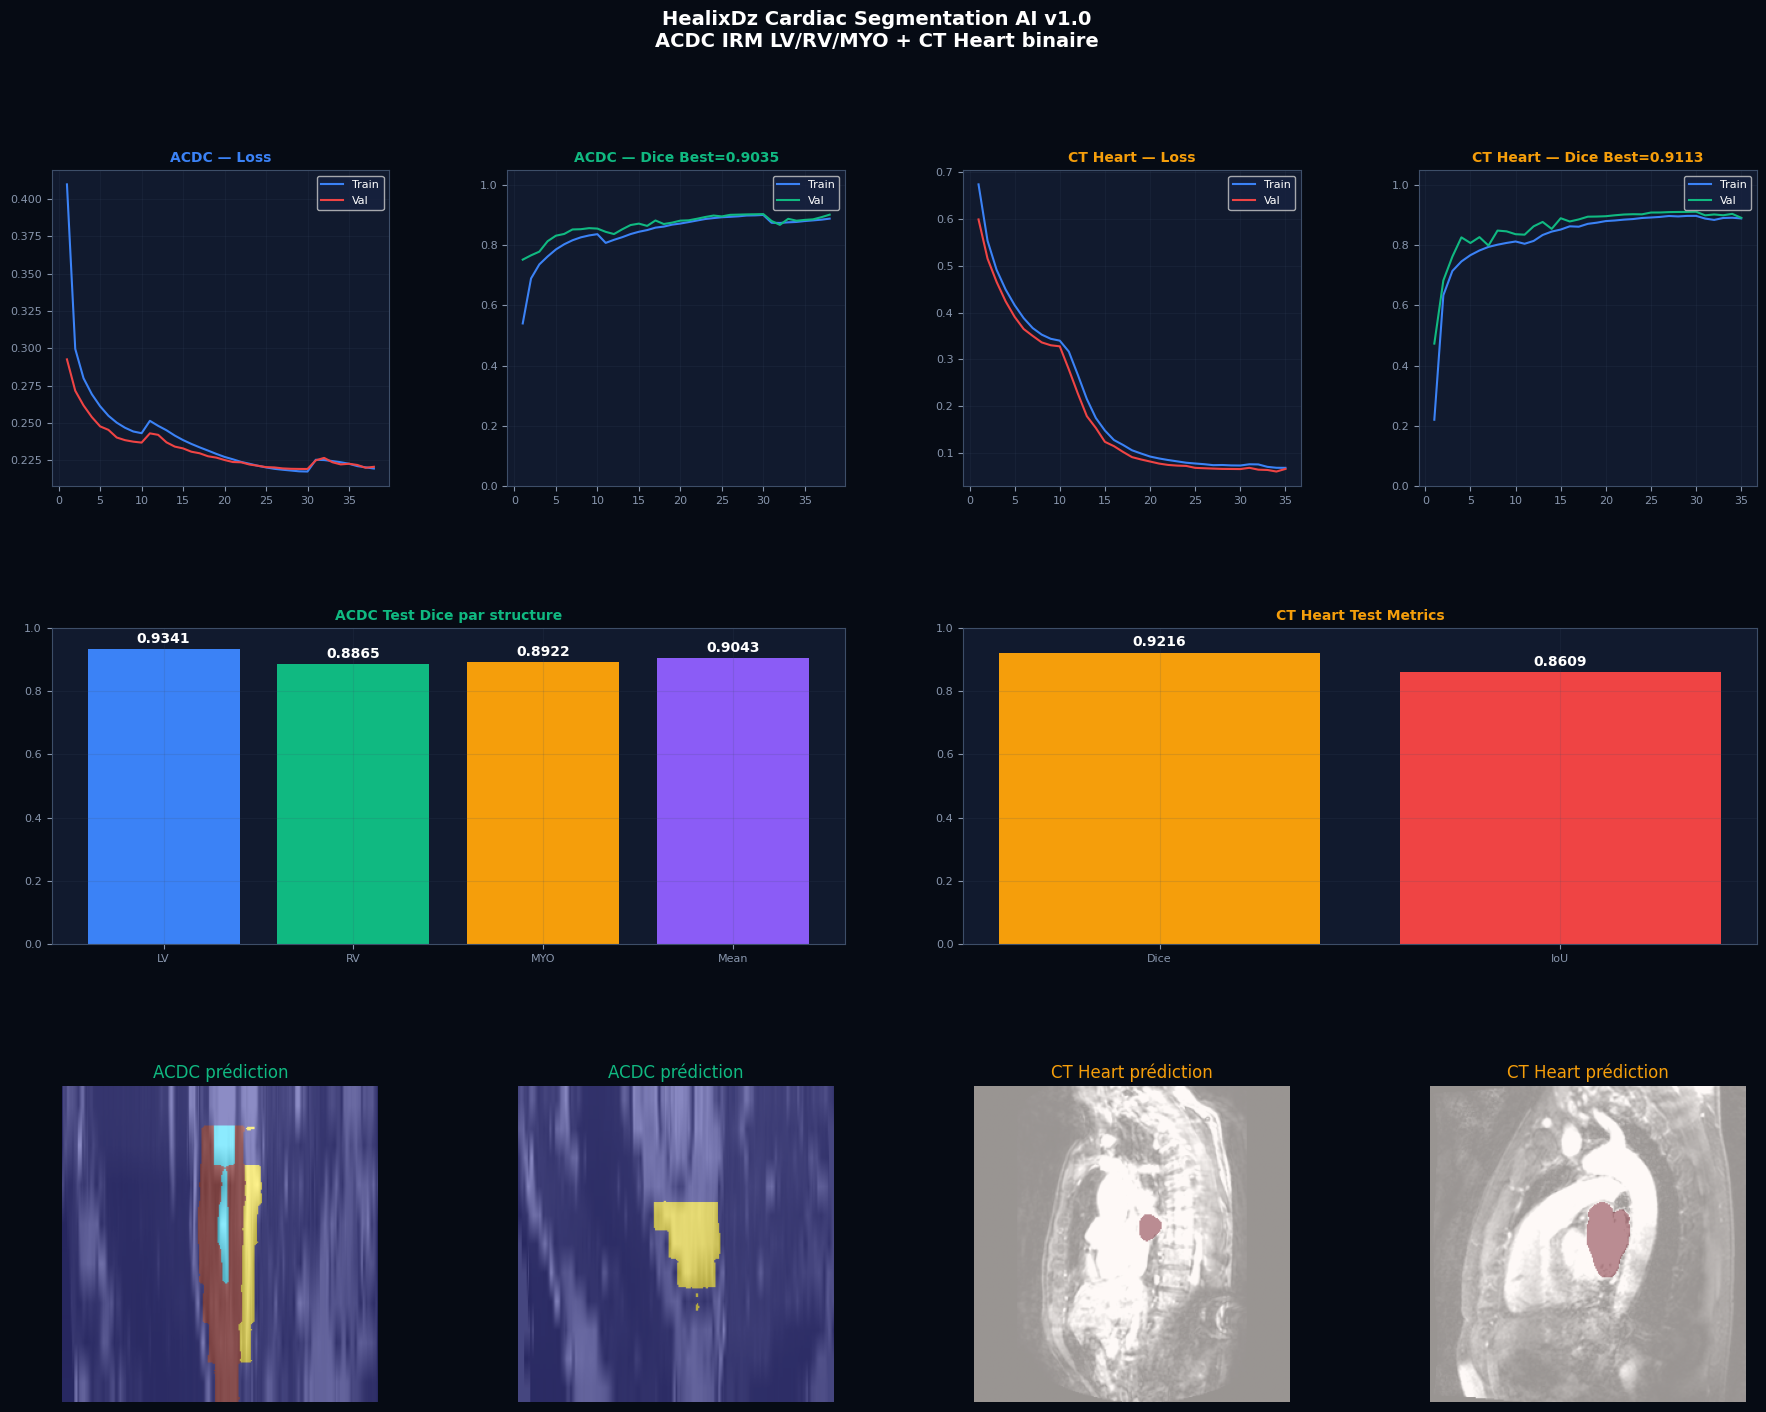

✅ Figure sauvegardée : /kaggle/working/healixdz_cardiac_seg_results.png


In [21]:
# ══════════════════════════════════════════════════════════════════
# CELLULE 13 — VISUALISATIONS FINALES
# ══════════════════════════════════════════════════════════════════

fig = plt.figure(figsize=(22, 16), facecolor="#060B14")
fig.suptitle("HealixDz Cardiac Segmentation AI v1.0\nACDC IRM LV/RV/MYO + CT Heart binaire",
             fontsize=14, fontweight="bold", color="white", y=0.98)
gs = gridspec.GridSpec(3, 4, figure=fig, hspace=0.45, wspace=0.35)

def style_ax(ax, title, color="white"):
    ax.set_facecolor("#111A2E")
    ax.set_title(title, color=color, fontsize=10, fontweight="bold")
    ax.tick_params(colors="#8896AD", labelsize=8)
    for sp in ax.spines.values():
        sp.set_edgecolor("#3D4E68")
    ax.grid(True, alpha=0.15, color="#3D4E68")

ax = fig.add_subplot(gs[0,0]); style_ax(ax, "ACDC — Loss", "#3B82F6")
if history_acdc["train_loss"]:
    ep = range(1, len(history_acdc["train_loss"])+1)
    ax.plot(ep, history_acdc["train_loss"], "#3B82F6", label="Train")
    ax.plot(ep, history_acdc["val_loss"], "#EF4444", label="Val")
    ax.legend(fontsize=8, facecolor="#172240", labelcolor="white")

ax = fig.add_subplot(gs[0,1]); style_ax(ax, f"ACDC — Dice Best={best_acdc:.4f}", "#10B981")
if history_acdc["train_metric"]:
    ep = range(1, len(history_acdc["train_metric"])+1)
    ax.plot(ep, history_acdc["train_metric"], "#3B82F6", label="Train")
    ax.plot(ep, history_acdc["val_metric"], "#10B981", label="Val")
    ax.legend(fontsize=8, facecolor="#172240", labelcolor="white")
    ax.set_ylim(0, 1.05)

ax = fig.add_subplot(gs[0,2]); style_ax(ax, "CT Heart — Loss", "#F59E0B")
if history_ct["train_loss"]:
    ep = range(1, len(history_ct["train_loss"])+1)
    ax.plot(ep, history_ct["train_loss"], "#3B82F6", label="Train")
    ax.plot(ep, history_ct["val_loss"], "#EF4444", label="Val")
    ax.legend(fontsize=8, facecolor="#172240", labelcolor="white")

ax = fig.add_subplot(gs[0,3]); style_ax(ax, f"CT Heart — Dice Best={best_ct:.4f}", "#F59E0B")
if history_ct["train_metric"]:
    ep = range(1, len(history_ct["train_metric"])+1)
    ax.plot(ep, history_ct["train_metric"], "#3B82F6", label="Train")
    ax.plot(ep, history_ct["val_metric"], "#10B981", label="Val")
    ax.legend(fontsize=8, facecolor="#172240", labelcolor="white")
    ax.set_ylim(0, 1.05)

ax = fig.add_subplot(gs[1,:2]); style_ax(ax, "ACDC Test Dice par structure", "#10B981")
names = ["LV", "RV", "MYO", "Mean"]
vals = [test_acdc["LV"], test_acdc["RV"], test_acdc["MYO"], test_acdc["mean"]]
ax.bar(names, vals, color=["#3B82F6", "#10B981", "#F59E0B", "#8B5CF6"])
ax.set_ylim(0,1)
for i,v in enumerate(vals):
    ax.text(i, v+0.02, f"{v:.4f}", ha="center", color="white", fontweight="bold")

ax = fig.add_subplot(gs[1,2:]); style_ax(ax, "CT Heart Test Metrics", "#F59E0B")
names = ["Dice", "IoU"]
vals = [test_ct["dice"], test_ct["iou"]]
ax.bar(names, vals, color=["#F59E0B", "#EF4444"])
ax.set_ylim(0,1)
for i,v in enumerate(vals):
    ax.text(i, v+0.02, f"{v:.4f}", ha="center", color="white", fontweight="bold")

def show_prediction_acdc(ax, idx=0):
    if not (out / CFG["acdc_model"]).exists() or len(acdc_test_ds) == 0:
        ax.axis("off"); return
    model = build_acdc_unet().to(device)
    ckpt = torch.load(out / CFG["acdc_model"], map_location=device, weights_only=False)
    model.load_state_dict(ckpt["model_state"]); model.eval()
    img, mask = acdc_test_ds[idx]
    with torch.no_grad():
        pred = torch.argmax(model(img.unsqueeze(0).to(device)), dim=1).squeeze().cpu().numpy()
    ax.imshow(denorm_img(img)); ax.imshow(pred, alpha=0.45, cmap="jet", vmin=0, vmax=3)
    ax.set_title("ACDC prédiction", color="#10B981"); ax.axis("off")

def show_prediction_ct(ax, idx=0):
    if not (out / CFG["ct_model"]).exists() or len(ct_test_ds) == 0:
        ax.axis("off"); return
    model = build_ct_unet().to(device)
    ckpt = torch.load(out / CFG["ct_model"], map_location=device, weights_only=False)
    model.load_state_dict(ckpt["model_state"]); model.eval()
    img, mask = ct_test_ds[idx]
    with torch.no_grad():
        pred = (torch.sigmoid(model(img.unsqueeze(0).to(device))) > 0.5).squeeze().cpu().numpy()
    ax.imshow(denorm_img(img)); ax.imshow(pred, alpha=0.45, cmap="Reds", vmin=0, vmax=1)
    ax.set_title("CT Heart prédiction", color="#F59E0B"); ax.axis("off")

show_prediction_acdc(fig.add_subplot(gs[2,0]), 0)
show_prediction_acdc(fig.add_subplot(gs[2,1]), min(1, max(0, len(acdc_test_ds)-1)))
show_prediction_ct(fig.add_subplot(gs[2,2]), 0)
show_prediction_ct(fig.add_subplot(gs[2,3]), min(1, max(0, len(ct_test_ds)-1)))

plt.savefig(f"{CFG['output_path']}/healixdz_cardiac_seg_results.png", dpi=150,
            bbox_inches="tight", facecolor="#060B14")
plt.show()
print("✅ Figure sauvegardée : /kaggle/working/healixdz_cardiac_seg_results.png")


In [22]:
# ══════════════════════════════════════════════════════════════════
# CELLULE 14 — SAUVEGARDE JSON + ZIP FINAL
# ══════════════════════════════════════════════════════════════════

metrics_json = {
    "version": "HealixDz Cardiac Segmentation AI v1.0",
    "task": "Segmentation Cardiaque IRM + CT",
    "datasets": {
        "ACDC": {
            "url": "kaggle.com/datasets/anhoangvo/acdc-dataset",
            "format": ".h5",
            "slices": len(acdc_index),
            "classes": ACDC_CLASSES,
        },
        "CT_Heart": {
            "url": "kaggle.com/datasets/andrewmvd/heart-segmentation-in-ct-images",
            "format": ".mhd + .raw/.zraw",
            "slices": len(ct_index),
            "classes": ["Background", "Heart"],
        },
    },
    "architecture": {
        "model": "U-Net",
        "encoder": CFG["encoder"],
        "encoder_weights": CFG["encoder_weights"],
        "img_size": CFG["img_size"],
    },
    "results": {
        "ACDC": {
            "file": CFG["acdc_model"],
            "val_best_dice": float(best_acdc),
            "test_LV": float(test_acdc["LV"]),
            "test_RV": float(test_acdc["RV"]),
            "test_MYO": float(test_acdc["MYO"]),
            "test_mean": float(test_acdc["mean"]),
        },
        "CT_Heart": {
            "file": CFG["ct_model"],
            "val_best_dice": float(best_ct),
            "test_dice": float(test_ct["dice"]),
            "test_iou": float(test_ct["iou"]),
        },
    },
}

out = Path(CFG["output_path"])
json_path = out / "healixdz_cardiac_seg_metrics.json"
with open(json_path, "w", encoding="utf-8") as f:
    json.dump(metrics_json, f, indent=2, ensure_ascii=False)

print("\n" + "═"*70)
print("FICHIERS SAUVEGARDÉS")
print("═"*70)
for fname in [CFG["acdc_model"], CFG["ct_model"], "healixdz_cardiac_seg_metrics.json", "healixdz_cardiac_seg_results.png"]:
    p = out / fname
    if p.exists():
        print(f"✅ {fname:<45} {p.stat().st_size/1e6:.1f} MB")
    else:
        print(f"❌ {fname}")

!zip -j /kaggle/working/healixdz_cardiac_segmentation_v1_outputs.zip /kaggle/working/*.pth /kaggle/working/healixdz_cardiac_seg_metrics.json /kaggle/working/healixdz_cardiac_seg_results.png

print("\n✅ ZIP prêt : /kaggle/working/healixdz_cardiac_segmentation_v1_outputs.zip")
print("\n" + "═"*70)
print("RÉSUMÉ FINAL — HealixDz Cardiac Segmentation AI v1.0")
print("═"*70)
print(f"ACDC Mean Dice : {test_acdc['mean']:.4f}")
print(f"CT Heart Dice  : {test_ct['dice']:.4f}")
print("═"*70)



══════════════════════════════════════════════════════════════════════
FICHIERS SAUVEGARDÉS
══════════════════════════════════════════════════════════════════════
✅ healixdz_cardiac_acdc_unet_best.pth           81.7 MB
✅ healixdz_cardiac_ct_heart_unet_best.pth       81.7 MB
✅ healixdz_cardiac_seg_metrics.json             0.0 MB
✅ healixdz_cardiac_seg_results.png              0.8 MB
  adding: healixdz_cardiac_acdc_unet_best.pth (deflated 7%)
  adding: healixdz_cardiac_ct_heart_unet_best.pth (deflated 8%)
  adding: healixdz_cardiac_seg_metrics.json (deflated 57%)
  adding: healixdz_cardiac_seg_results.png (deflated 3%)

✅ ZIP prêt : /kaggle/working/healixdz_cardiac_segmentation_v1_outputs.zip

══════════════════════════════════════════════════════════════════════
RÉSUMÉ FINAL — HealixDz Cardiac Segmentation AI v1.0
══════════════════════════════════════════════════════════════════════
ACDC Mean Dice : 0.9043
CT Heart Dice  : 0.9216
═══════════════════════════════════════════════════════